# InceptionTime 1D
Implementazione compatta dei blocchi Inception per classificazione di time series multicanale. Raw input, normalizzazione stimata sul training fold, pooling con maschera delle lunghezze e early stopping su validation interna. Dipendenza: PyTorch.

In [1]:
import config as cfg, utils, advanced_models as adv
utils.print_versions()
adv.print_versions()
utils.print_config()
print('canali:', cfg.QUICK_TORCH_CHANNELS if cfg.QUICK_TEST else cfg.TORCH_CHANNELS)
MODEL = 'inceptiontime'

Python      : 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
numpy       : 2.5.4
pandas      : 3.0.6
scipy       : 1.18.1
sklearn     : 1.9.1
catboost    : 1.2.10
matplotlib  : 3.11.2
natsort     : 8.4.0
tqdm        : 4.70.1
Python: 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
xgboost: 3.4.1
sktime: 1.2.0
torch: 2.14.1
SEED=89  N_SPLITS=10  CV_MODE=stratified  QUICK_TEST=False
FALL_CLASSES: {'UniMiB': [9, 10, 11, 12, 13, 14, 15, 16], 'UniZgFall': [5, 6, 7]}
canali: (32, 64, 128)


## Cross-validation, metriche e predizioni

In [2]:
adv.run_all(MODEL)

[inceptiontime | UniZgFall | raw] X=(468, 3, 5150), classi=10, CV=stratified, fold=10
Parametri: max_epochs=30, batch_size=64, lr=0.001, weight_decay=0.0001


inceptiontime|UniZgFall:   0%|          | 0/10 [00:00<?, ?it/s]

[inceptiontime | UniZgFall | raw | fold 1/10] train su 421 esempi, test su 47
fit in corso...


/home/agrume/Desktop/projects/thesis/fall_detection_ml/advanced_models.py:296: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  y_tensor = torch.from_numpy(np.asarray(y, dtype=np.int64))


  epoch 1/30: train_loss=2.7926, val_loss=2.2798, val_acc=0.1647
  epoch 2/30: train_loss=1.4535, val_loss=2.0740, val_acc=0.3647
  epoch 3/30: train_loss=1.0629, val_loss=1.7650, val_acc=0.5176
  epoch 4/30: train_loss=0.8142, val_loss=1.4986, val_acc=0.4941
  epoch 5/30: train_loss=0.6499, val_loss=1.1402, val_acc=0.7176
  epoch 6/30: train_loss=0.5778, val_loss=0.9490, val_acc=0.7412
  epoch 7/30: train_loss=0.4741, val_loss=0.8483, val_acc=0.7882
  epoch 8/30: train_loss=0.4201, val_loss=0.6969, val_acc=0.8000
  epoch 9/30: train_loss=0.3315, val_loss=0.6860, val_acc=0.8000
  epoch 10/30: train_loss=0.2966, val_loss=0.5978, val_acc=0.8353
  epoch 11/30: train_loss=0.2480, val_loss=0.5447, val_acc=0.8706
  epoch 12/30: train_loss=0.2167, val_loss=0.5316, val_acc=0.8941
  epoch 13/30: train_loss=0.2105, val_loss=0.4803, val_acc=0.8824
  epoch 14/30: train_loss=0.1957, val_loss=0.4371, val_acc=0.9059
  epoch 15/30: train_loss=0.1518, val_loss=0.5135, val_acc=0.8706
  epoch 16/30: trai

inceptiontime|UniMiB:   0%|          | 0/10 [00:00<?, ?it/s]

[inceptiontime | UniMiB | raw | fold 1/10] train su 1782 esempi, test su 198
fit in corso...
  epoch 1/30: train_loss=2.7538, val_loss=2.4879, val_acc=0.2941
  epoch 2/30: train_loss=1.9470, val_loss=1.9275, val_acc=0.3697
  epoch 3/30: train_loss=1.6389, val_loss=1.6508, val_acc=0.4622
  epoch 4/30: train_loss=1.3649, val_loss=1.5640, val_acc=0.4902
  epoch 5/30: train_loss=1.2090, val_loss=1.3634, val_acc=0.5406
  epoch 6/30: train_loss=0.9848, val_loss=1.2671, val_acc=0.5910
  epoch 7/30: train_loss=0.7906, val_loss=1.1059, val_acc=0.5994
  epoch 8/30: train_loss=0.6367, val_loss=1.1257, val_acc=0.6218
  epoch 9/30: train_loss=0.5380, val_loss=1.0328, val_acc=0.6443
  epoch 10/30: train_loss=0.4401, val_loss=1.0301, val_acc=0.6303
  epoch 11/30: train_loss=0.3943, val_loss=1.0260, val_acc=0.6555
  epoch 12/30: train_loss=0.3011, val_loss=0.9769, val_acc=0.6835
  epoch 13/30: train_loss=0.2387, val_loss=0.9728, val_acc=0.6751
  epoch 14/30: train_loss=0.2031, val_loss=0.9944, val_acc

## Riepilogo

In [3]:
display(adv.summary_table(MODEL))

,dataset,input,accuracy,f1_macro,precision_macro,recall_macro,fit_time,predict_time,fall_sensitivity,fall_specificity,fall_precision
0,UniZgFall,raw,0.9125 ± 0.0452,0.8875 ± 0.0743,0.9071 ± 0.0652,0.8850 ± 0.0712,7.1504 ± 1.2171,0.0125 ± 0.0002,0.8836 ± 0.1092,0.9863 ± 0.0192,0.9465 ± 0.0772
1,UniMiB,raw,0.6707 ± 0.0299,0.6837 ± 0.0300,0.7019 ± 0.0333,0.6895 ± 0.0318,16.0354 ± 1.8573,0.0343 ± 0.0008,0.9944 ± 0.0055,0.9852 ± 0.0078,0.9944 ± 0.0029


## Grafici e curve di apprendimento

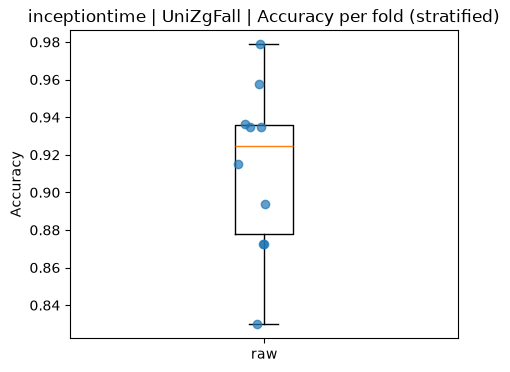

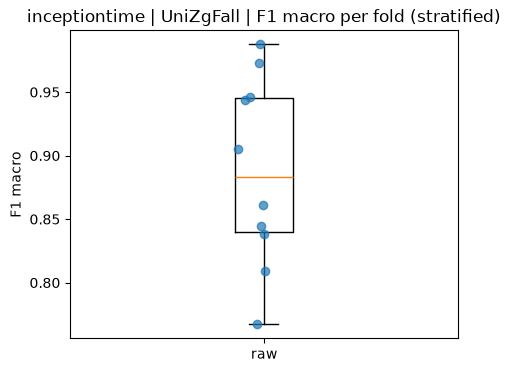

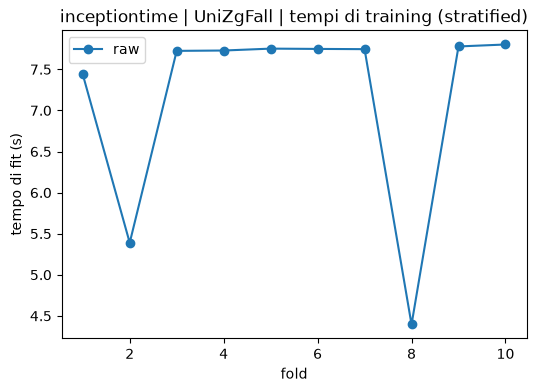

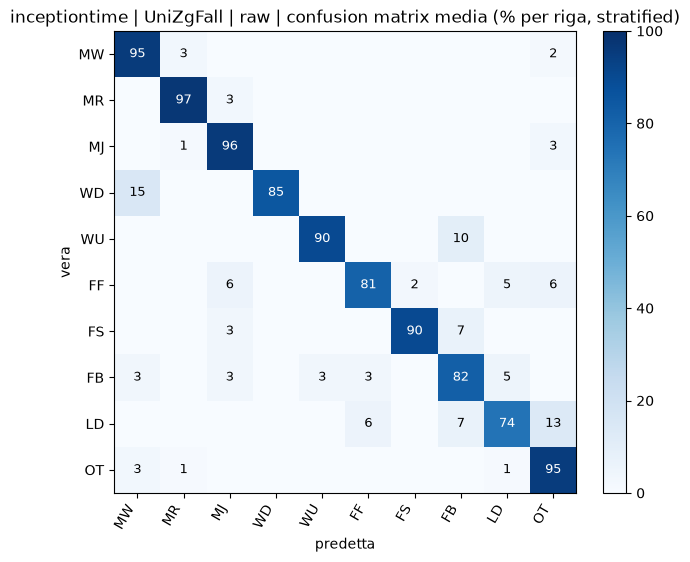

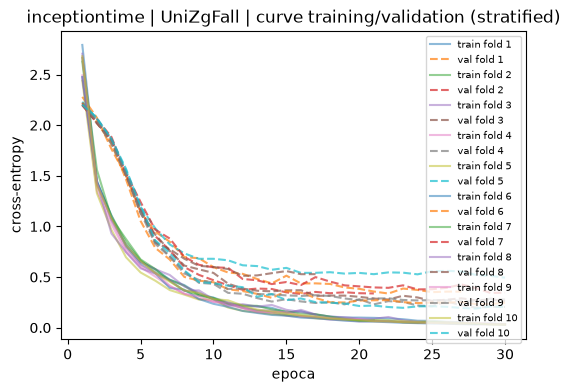

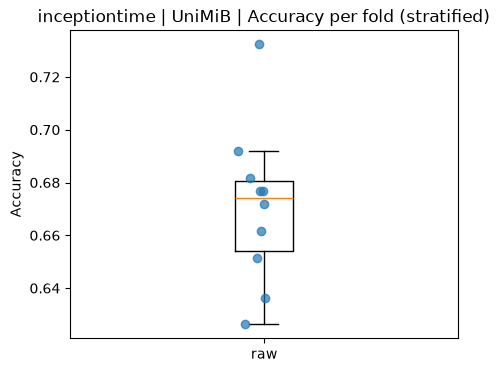

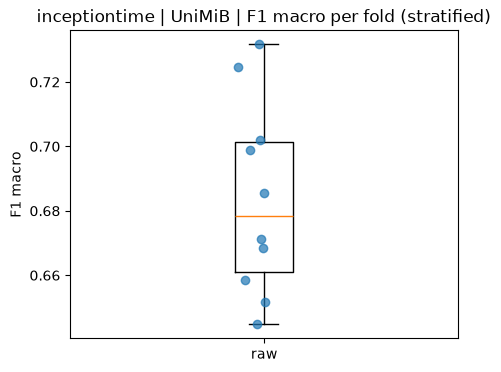

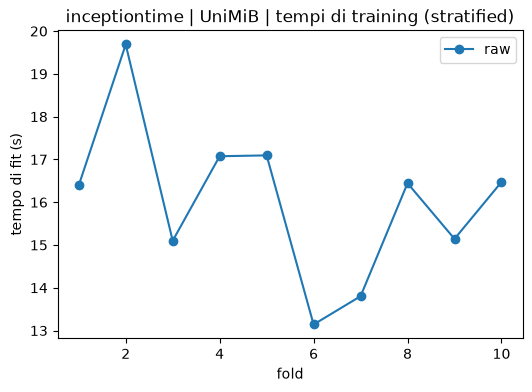

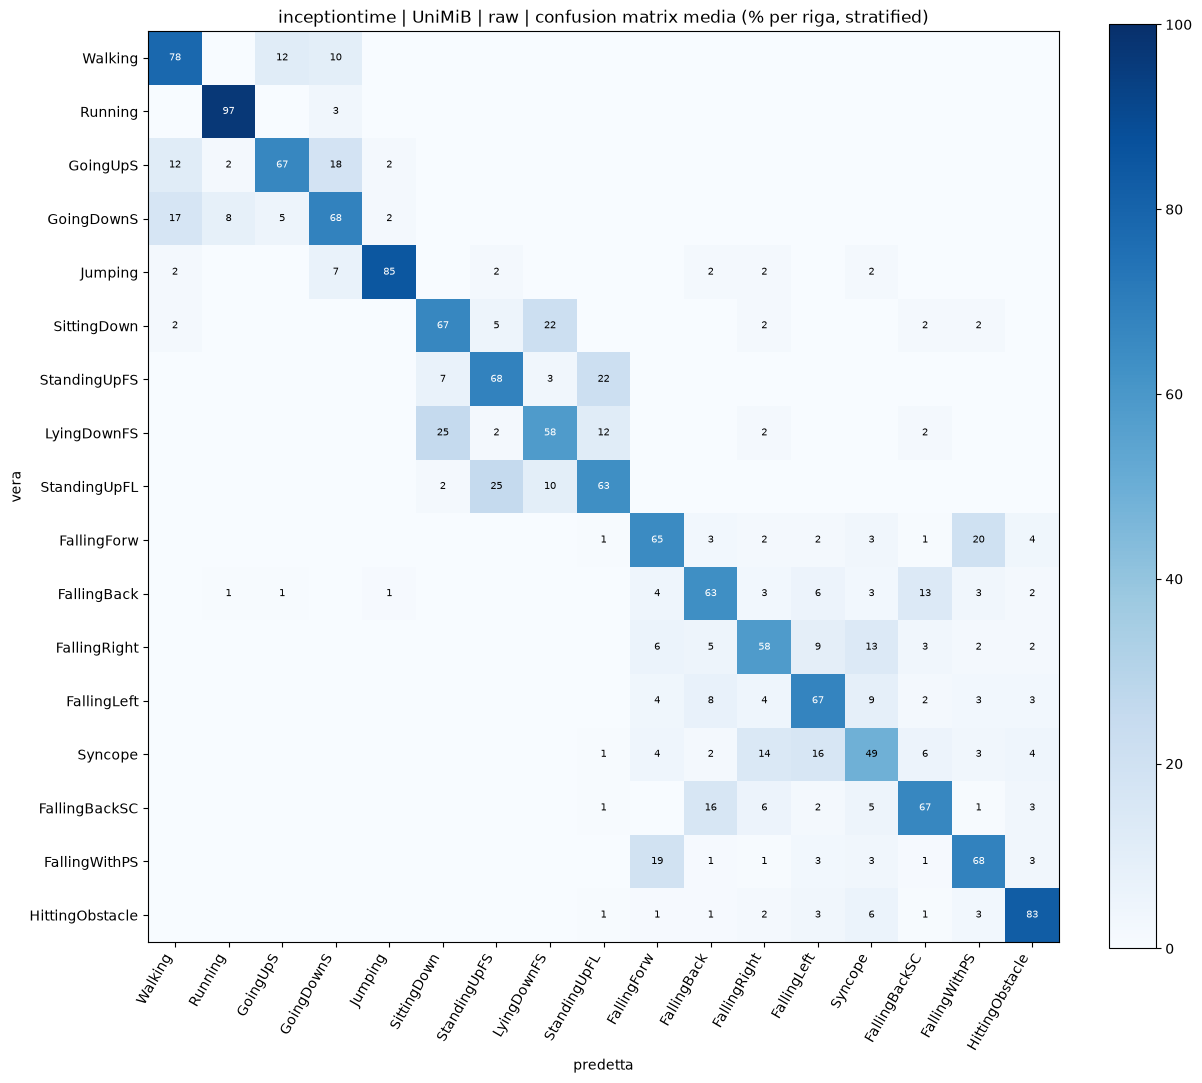

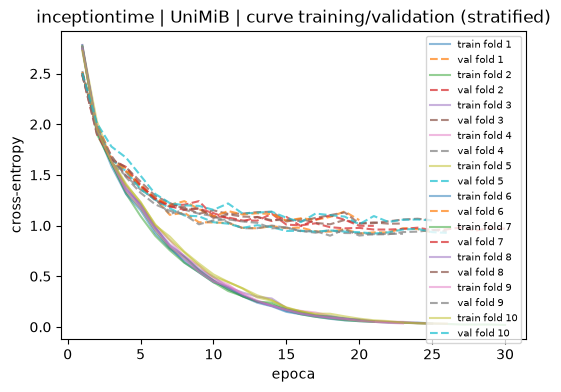

In [4]:
adv.plot_all(MODEL)